# DBP15K Dataset Structure

In [3]:
# base_path = 'C:\\Users\\Partiran\\Desktop\\TKG\\dbp15k'
base_path = 'dbp15k'

def parse_directory(path, n):
    print(n*'   ' + os.path.basename(path))
    if not os.path.isdir(path):
        pass
    else:
        n += 1
        for each in os.listdir(path):
            # print(each)
            
            new_path = path + '\\' + each
            parse_directory(new_path, n)


for each in os.listdir(base_path):
    path = base_path + '\\' + each
    parse_directory(path, 0)

en_all_attrs_range
fr_en
   0_1
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   0_2
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   0_3
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   0_4
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   0_5
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   all_attrs_range
   ent_ILLs
   mtranse
      0_1
         ent_ids_1
         ent_ids_2
         ref_pairs
      

## save as json

In [4]:
import os
import json

base_path = r'C:\Users\Partiran\Desktop\dbp15k'

def directory_to_dict(path):
    if os.path.isfile(path):
        return None  # file

    result = {}

    for item in os.listdir(path):
        full_path = os.path.join(path, item)

        if os.path.isdir(full_path):
            result[item] = directory_to_dict(full_path)
        else:
            result[item] = "file"

    return result

tree = {
    os.path.basename(base_path): directory_to_dict(base_path)
}

with open("directory_structure.json", "w", encoding="utf-8") as f:
    json.dump(tree, f, indent=4)

print("Saved to directory_structure.json")

Saved to directory_structure.json


# Temporal Analysis

In [10]:
import os
from collections import Counter

def analyze_temporal_facts(base_path, language_pair="fr_en", fold="0_1"):
    path = f"{base_path}/dbp15k/{language_pair}/{fold}"
    
    # Load relation mappings
    def load_rel_mapping(file_path):
        mapping = {}
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                parts = line.strip().split('\t') if '\t' in line else line.strip().split()
                if len(parts) >= 2:
                    rel_id = parts[0]
                    rel_name = parts[1]
                    mapping[rel_id] = rel_name
        return mapping
    
    rel_mapping_1 = load_rel_mapping(f"{path}/rel_ids_1")
    rel_mapping_2 = load_rel_mapping(f"{path}/rel_ids_2")
    
    temporal_keywords = ["date", "naissance", "décès", "birth", "death", "start", "end", 
                         "création", "période", "année", "début", "fin", "fondation"]
    
    total_triples = 0
    temporal_triples = 0
    temporal_rels = Counter()
    
    for kg in ['triples_1', 'triples_2']:
        file_path = f"{path}/{kg}"
        if not os.path.exists(file_path):
            continue
            
        mapping = rel_mapping_1 if kg == 'triples_1' else rel_mapping_2
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                total_triples += 1
                parts = line.strip().split()
                if len(parts) >= 3:
                    rel_id = parts[1]
                    rel_name = mapping.get(rel_id, f"ID_{rel_id}")
                    
                    rel_lower = rel_name.lower()
                    if any(kw in rel_lower for kw in temporal_keywords):
                        temporal_triples += 1
                        temporal_rels[rel_name] += 1
    
    percentage = (temporal_triples / total_triples * 100) if total_triples > 0 else 0
    
    print(f"=== TEMPORAL ANALYSIS: {language_pair} / {fold} ===")
    print(f"Total Triples     : {total_triples:,}")
    print(f"Temporal Triples  : {temporal_triples:,}")
    print(f"Percentage        : {percentage:.3f}%")
    print("\nTop Temporal Relations:")
    for rel, count in temporal_rels.most_common(15):
        print(f"  {rel:<40} : {count:,}")
    
    return percentage

# Run it
if __name__ == "__main__":
    base_path = r"C:\Users\Partiran\Desktop"
    analyze_temporal_facts(base_path, language_pair="fr_en", fold="0_1")

=== TEMPORAL ANALYSIS: fr_en / 0_1 ===
Total Triples     : 221,720
Temporal Triples  : 13,777
Percentage        : 6.214%

Top Temporal Relations:
  http://dbpedia.org/property/birthPlace   : 5,799
  http://fr.dbpedia.org/property/lieuDeNaissance : 2,499
  http://dbpedia.org/property/deathPlace   : 2,247
  http://fr.dbpedia.org/property/lieuDeDécès : 1,201
  http://dbpedia.org/property/placeOfBirth : 823
  http://dbpedia.org/property/placeOfDeath : 221
  http://fr.dbpedia.org/property/lieuNaissance : 177
  http://dbpedia.org/property/birthplace   : 122
  http://fr.dbpedia.org/property/fondateur : 86
  http://fr.dbpedia.org/property/reléguéFin : 78
  http://fr.dbpedia.org/property/paysDeNaissance : 76
  http://fr.dbpedia.org/property/promuDébut : 67
  http://fr.dbpedia.org/property/paysDeDécès : 47
  http://fr.dbpedia.org/property/débuts    : 32
  http://fr.dbpedia.org/property/finaliste : 29


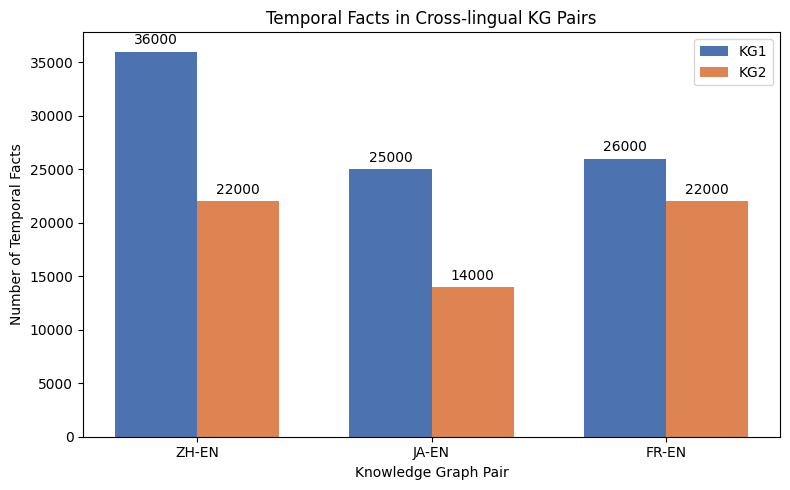

In [3]:
import numpy as np
import matplotlib.pyplot as plt

pairs = ['ZH-EN', 'JA-EN', 'FR-EN']

# #Time values
kg1 = [36000, 25000, 26000]
kg2 = [22000, 14000, 22000]

x = np.arange(len(pairs))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(
    x - width/2,
    kg1,
    width,
    label='KG1',
    color='#4C72B0'   # blue
)

bars2 = plt.bar(
    x + width/2,
    kg2,
    width,
    label='KG2',
    color='#DD8452'   # orange
)

plt.xticks(x, pairs)
plt.ylabel('Number of Temporal Facts')
plt.xlabel('Knowledge Graph Pair')
plt.title('Temporal Facts in Cross-lingual KG Pairs')
plt.legend()

# Value labels
for bars in [bars1, bars2]:
    plt.bar_label(bars, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

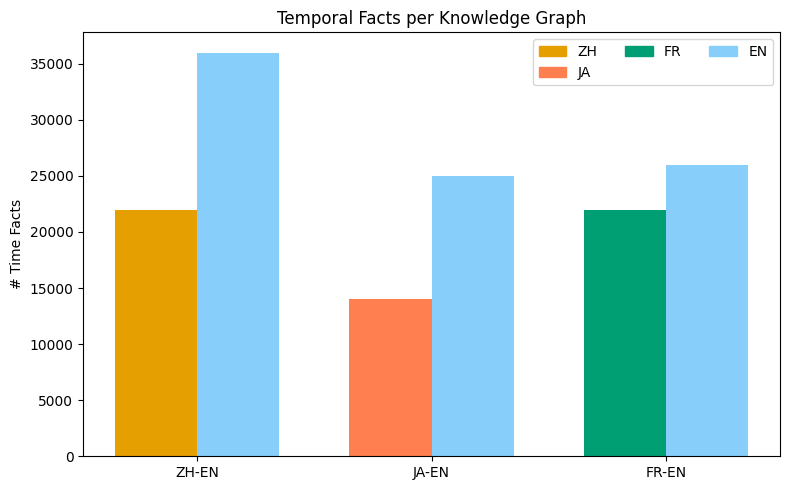

In [13]:
import numpy as np
import matplotlib.pyplot as plt

colors = {
    'ZH': '#E69F00',   # orange
    'JA': '#56B4E9',   # light blue
    'FR': '#009E73',   # green
    'EN': '#0072B2',   # dark blue
    'DBP': '#CC79A7',  # purple
    'WD': '#D55E00'    # vermillion
}

pairs = ['ZH-EN', 'JA-EN', 'FR-EN']

left_labels  = ['ZH', 'JA', 'FR']
right_labels = ['EN', 'EN', 'EN']

# left_values  = [36000, 25000, 26000]
# right_values = [22000, 14000, 22000]

left_values  = [22000, 14000, 22000]
right_values = [36000, 25000, 26000]

x = np.arange(len(pairs))
width = 0.35

colors = {
    'ZH': '#E69F00',
    # 'JA': '#56B4E9',
    'JA': 'coral',
    'FR': '#009E73',
    # 'EN': '#0072B2',
    'EN': 'lightskyblue'
}

fig, ax = plt.subplots(figsize=(8,5))

for i in range(len(pairs)):
    ax.bar(
        x[i] - width/2,
        left_values[i],
        width,
        color=colors[left_labels[i]]
    )

    ax.bar(
        x[i] + width/2,
        right_values[i],
        width,
        color=colors[right_labels[i]]
    )

ax.set_xticks(x)
ax.set_xticklabels(pairs)
ax.set_ylabel('# Time Facts')
ax.set_title('Temporal Facts per Knowledge Graph')

# Custom legend
handles = [
    plt.Rectangle((0,0),1,1,color=colors['ZH']),
    plt.Rectangle((0,0),1,1,color=colors['JA']),
    plt.Rectangle((0,0),1,1,color=colors['FR']),
    plt.Rectangle((0,0),1,1,color=colors['EN']),
]

ax.legend(handles,
          ['ZH','JA','FR','EN'],
          ncol=3)

plt.tight_layout()
plt.show()

# TKGL-Wikidata

In [2]:
import requests

def get_label(qid, languages=["en", "fr", "de", "es"]):
    url = "https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbgetentities",
        "ids": qid,
        "props": "labels",
        "languages": "|".join(languages),
        "format": "json"
    }
    headers = {
        'User-Agent': 'MyTKGProject/1.0 (your.email@example.com)'  # ← Important!
    }
    
    response = requests.get(url, params=params, headers=headers)
    
    print("Status:", response.status_code)        # Debug
    print("Content-Type:", response.headers.get('Content-Type'))
    
    if response.status_code != 200:
        print("Error text:", response.text[:500])
        return {"error": f"HTTP {response.status_code}"}
    
    data = response.json()
    # ... rest of your code
    
    entity = data["entities"].get(qid)
    if entity and "labels" in entity:
        labels = {lang: entity["labels"][lang]["value"] 
                 for lang in languages if lang in entity["labels"]}
        return labels
    return {"error": "No labels found"}

# Test
print(get_label("Q33155"))

Status: 200
Content-Type: application/json; charset=utf-8
{'en': 'Rome–Civita Castellana–Viterbo railway', 'fr': 'ligne urbaine Roma-Civita Castellana-Viterbe', 'de': 'Bahnstrecke Rom–Civita Castellana–Viterbo'}


In [3]:
print(get_label("Q331755"))


Status: 200
Content-Type: application/json; charset=utf-8
{'en': 'Sverre of Norway', 'fr': 'Sverre de Norvège', 'de': 'Sverre', 'es': 'Sverre I de Noruega'}


In [4]:
print(get_label("Q1294765"))

Status: 200
Content-Type: application/json; charset=utf-8
{'en': 'Monarch of Norway', 'fr': 'Monarchie norvégienne', 'de': 'Norwegische Monarchie', 'es': 'Monarca de Noruega'}


In [6]:
print(get_label("Q553893"))

Status: 200
Content-Type: application/json; charset=utf-8
{'en': 'Charles Emmanuel, Landgrave of Hesse-Rotenburg', 'fr': 'Charles-Emmanuel de Hesse-Rheinfels-Rotenbourg', 'de': 'Karl Emanuel', 'es': 'Carlos Manuel de Hesse-Rotenburg'}


In [7]:
print(get_label("Q63407940"))

Status: 200
Content-Type: application/json; charset=utf-8
{'fr': 'landgrave de Hesse-Rheinfels-Rotenbourg'}


In [5]:
import requests

def get_property_label(pid, languages=["en", "fr", "de", "es"]):
    """Get labels for a Wikidata property (P39, P348, etc.)"""
    url = "https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbgetentities",
        "ids": pid,           # e.g. "P39"
        "props": "labels",
        "languages": "|".join(languages),
        "format": "json"
    }
    headers = {
        'User-Agent': 'MyTKGProject/1.0 (your.email@example.com)'   # ← Very important!
    }
    
    response = requests.get(url, params=params, headers=headers)
    
    if response.status_code != 200:
        print("Error:", response.status_code)
        print(response.text[:300])
        return {"error": f"HTTP {response.status_code}"}
    
    data = response.json()
    entity = data["entities"].get(pid)
    
    if entity and "labels" in entity:
        labels = {lang: entity["labels"][lang]["value"] 
                 for lang in languages if lang in entity["labels"]}
        return labels
    return {"error": "No labels found"}

# Test with one from your screenshot
print(get_property_label("P39"))

{'en': 'position held', 'fr': 'fonction', 'de': 'öffentliches Amt oder Stellung', 'es': 'cargo ocupado'}


# Creating a new cross-lingual TKG from Wikidata

## filtering valid quadruples from tkgl-wikidata dataset

In [10]:
import pandas as pd
import requests
import time
from tqdm import tqdm

# ================== CONFIG ==================
FILE_PATH = r'C:\Users\Partiran\Desktop\TKG\tkgl-wikidata_edgelist.csv'
LANGUAGES = ["en"]           # Start with English only
MIN_LANGS_REQUIRED = 1
MAX_QIDS = 2000              # Small but reasonable for testing
# ===========================================

print("Loading dataset...")
df = pd.read_csv(FILE_PATH)
print(f"Original rows: {len(df)} | Time range: {df['ts'].min()}–{df['ts'].max()}")

all_qids = pd.concat([df['head'], df['tail']]).unique()
sample_qids = list(all_qids)[:MAX_QIDS]
print(f"Sampling {len(sample_qids)} QIDs...")

def get_multi_lang_labels(qids, languages=LANGUAGES):
    results = {}
    chunks = [qids[i:i+50] for i in range(0, len(qids), 50)]   # ← Much smaller chunks (safe limit)
    
    for i, chunk in enumerate(tqdm(chunks, desc="Fetching labels")):
        ids_str = "|".join(chunk)
        url = "https://www.wikidata.org/w/api.php"
        params = {
            "action": "wbgetentities",
            "ids": ids_str,
            "props": "labels",
            "languages": "|".join(languages),
            "format": "json"
        }
        headers = {'User-Agent': 'CrossLingualTKG-Debug/1.0 (your.email@example.com)'}
        
        try:
            resp = requests.get(url, params=params, headers=headers, timeout=15)
            # print(f"Chunk {i+1} Status: {resp.status_code}")   # uncomment if needed
            
            if resp.status_code == 200:
                data = resp.json()
                
                # Handle error response from Wikidata
                if "error" in data:
                    print(f"API Error: {data['error']}")
                    continue
                
                if "entities" not in data:
                    print("No 'entities' key in response")
                    continue
                
                for qid in chunk:
                    entity = data["entities"].get(qid)
                    if entity and "labels" in entity:
                        lang_labels = {lang: entity["labels"][lang]["value"] 
                                     for lang in languages if lang in entity["labels"]}
                        if lang_labels:
                            results[qid] = lang_labels
        except Exception as e:
            print(f"Exception in chunk {i+1}: {e}")
        
        time.sleep(0.6)   # polite delay
    
    return results

print("Starting label fetch...")
qid_multi_labels = get_multi_lang_labels(sample_qids)

print(f"\nSuccessfully labeled QIDs: {len(qid_multi_labels)}")

valid_qids = {qid: labels for qid, labels in qid_multi_labels.items() 
              if len(labels) >= MIN_LANGS_REQUIRED}

print(f"Valid QIDs: {len(valid_qids)}")

# Filter the dataframe
valid_mask = (df['head'].isin(valid_qids)) & (df['tail'].isin(valid_qids))
df_filtered = df[valid_mask].copy()

print(f"Remaining quadruples: {len(df_filtered)}")

if len(df_filtered) > 0:
    for lang in LANGUAGES:
        df_filtered[f'head_label_{lang}'] = df_filtered['head'].map(
            lambda q: valid_qids.get(q, {}).get(lang, q))
        df_filtered[f'tail_label_{lang}'] = df_filtered['tail'].map(
            lambda q: valid_qids.get(q, {}).get(lang, q))
    
    df_filtered.to_csv("tkgl_filtered_en.csv", index=False)
    print("✅ Saved tkgl_filtered_en.csv")
    print("\nPreview:")
    print(df_filtered.head(5))
else:
    print("Still empty - please paste the new console output.")

Loading dataset...
Original rows: 9856203 | Time range: 0–2024
Sampling 2000 QIDs...
Starting label fetch...


Fetching labels: 100%|█████████████████████████████████████████████████████████████████| 40/40 [01:11<00:00,  1.79s/it]



Successfully labeled QIDs: 1949
Valid QIDs: 1949
Remaining quadruples: 35443
✅ Saved tkgl_filtered_en.csv

Preview:
    ts    head     tail relation_type head_label_en        tail_label_en
42   6  Q47492    Q2277           P17     Gaza City         Roman Empire
51   7  Q47492    Q2277           P17     Gaza City         Roman Empire
61   8  Q47492    Q2277           P17     Gaza City         Roman Empire
72   9  Q47492    Q2277           P17     Gaza City         Roman Empire
77   9   Q1411  Q236259           P26      Claudius  Plautia Urgulanilla


In [4]:
for each in os.listdir():
    if each.endswith('csv'):
        print(each)

tkgl_wikidata_filtered_en_fr.csv


In [1]:
import pandas as pd
import requests
import time
from tqdm import tqdm

df = pd.read_csv("tkgl_filtered_en.csv")
print(f"Loaded {len(df)} rows")

# Get unique QIDs from the filtered file
all_qids = pd.concat([df['head'], df['tail']]).unique()
print(f"Unique QIDs: {len(all_qids)}")

LANGUAGES = ["fr"]          # Change to "de", "es", etc. if you prefer

def get_multi_lang_labels(qids, languages=LANGUAGES):
    results = {}
    chunks = [qids[i:i+50] for i in range(0, len(qids), 50)]
    
    for chunk in tqdm(chunks, desc=f"Fetching {languages[0]} labels"):
        ids_str = "|".join(chunk)
        url = "https://www.wikidata.org/w/api.php"
        params = {
            "action": "wbgetentities",
            "ids": ids_str,
            "props": "labels",
            "languages": "|".join(languages),
            "format": "json"
        }
        headers = {'User-Agent': 'CrossLingualTKG/1.0 (your.email@example.com)'}
        
        try:
            resp = requests.get(url, params=params, headers=headers, timeout=15)
            if resp.status_code == 200:
                data = resp.json()
                if "error" not in data and "entities" in data:
                    for qid in chunk:
                        entity = data["entities"].get(qid)
                        if entity and "labels" in entity:
                            lang_labels = {lang: entity["labels"][lang]["value"] 
                                         for lang in languages if lang in entity["labels"]}
                            if lang_labels:
                                results[qid] = lang_labels
        except:
            pass
        time.sleep(0.6)
    
    return results

print("Fetching second language labels...")
second_lang_labels = get_multi_lang_labels(all_qids)

print(f"Successfully got {len(second_lang_labels)} labels in {LANGUAGES[0]}")

# Merge into the dataframe
lang = LANGUAGES[0]
df[f'head_label_{lang}'] = df['head'].map(lambda q: second_lang_labels.get(q, {}).get(lang, None))
df[f'tail_label_{lang}'] = df['tail'].map(lambda q: second_lang_labels.get(q, {}).get(lang, None))

# Keep only rows that have labels in BOTH languages
df_cross = df.dropna(subset=[f'head_label_{lang}', f'tail_label_{lang}']).copy()

print(f"Final cross-lingual quadruples: {len(df_cross)}")

df_cross.to_csv(f"tkgl_cross_en_{lang}.csv", index=False)
print(f"✅ Saved tkgl_cross_en_{lang}.csv")

Loaded 35443 rows
Unique QIDs: 207
Fetching second language labels...


Fetching fr labels: 100%|████████████████████████████████████████████████████████████████| 5/5 [00:12<00:00,  2.56s/it]


Successfully got 187 labels in fr
Final cross-lingual quadruples: 30282
✅ Saved tkgl_cross_en_fr.csv


# Splitting and creating cross-linguual RKG

In [2]:
import pandas as pd
import numpy as np

# ================== CONFIG ==================
INPUT_FILE = "tkgl_cross_en_fr.csv"
LANG_A = "en"
LANG_B = "fr"
SHARED_RATIO = 0.25      # 20-30% shared entities is reasonable
NUM_SEEDS = 1000
RANDOM_SEED = 42
# ===========================================

np.random.seed(RANDOM_SEED)

print("Loading cross-lingual dataset...")
df = pd.read_csv(INPUT_FILE)
print(f"Loaded {len(df)} quadruples")

# 1. Split ENTITIES
all_entities = pd.concat([df['head'], df['tail']]).unique()
np.random.shuffle(all_entities)

n = len(all_entities)
n_shared = int(SHARED_RATIO * n)
n_rest = n - n_shared
n_a_only = n_rest // 2
n_b_only = n_rest - n_a_only

shared_ents = set(all_entities[:n_shared])
a_only = set(all_entities[n_shared : n_shared + n_a_only])
b_only = set(all_entities[n_shared + n_a_only:])

ents_a = shared_ents | a_only
ents_b = shared_ents | b_only

print(f"Shared entities: {len(shared_ents)}")
print(f"{LANG_A}-only: {len(a_only)}")
print(f"{LANG_B}-only: {len(b_only)}")

# 2. Assign quadruples (both endpoints must belong to the KG)
in_a = df['head'].isin(ents_a) & df['tail'].isin(ents_a)
in_b = df['head'].isin(ents_b) & df['tail'].isin(ents_b)

df_a = df[in_a].copy()
df_b = df[in_b].copy()

dropped = len(df) - len(df_a) - len(df_b)
print(f"TKG_{LANG_A}: {len(df_a)} facts")
print(f"TKG_{LANG_B}: {len(df_b)} facts")
print(f"Dropped facts (cross-KG): {dropped}")

# 3. True overlapping entities for seeds
present_a = set(pd.concat([df_a['head'], df_a['tail']]).unique())
present_b = set(pd.concat([df_b['head'], df_b['tail']]).unique())
true_overlap = list(present_a & present_b)

print(f"True overlapping entities: {len(true_overlap)}")

num_seeds = min(NUM_SEEDS, len(true_overlap))
seed_entities = np.random.choice(true_overlap, num_seeds, replace=False)

# 4. Build label maps (more robust)
label_map_a = {}
label_map_b = {}

for _, row in df.iterrows():
    h = row['head']
    t = row['tail']
    label_map_a[h] = row.get(f'head_label_{LANG_A}', h)
    label_map_a[t] = row.get(f'tail_label_{LANG_A}', t)
    label_map_b[h] = row.get(f'head_label_{LANG_B}', h)
    label_map_b[t] = row.get(f'tail_label_{LANG_B}', t)

# 5. Save
df_a.to_csv(f"tkg_{LANG_A}.csv", index=False)
df_b.to_csv(f"tkg_{LANG_B}.csv", index=False)

seeds_df = pd.DataFrame({
    'entity_id': seed_entities,
    f'label_{LANG_A}': [label_map_a.get(e, e) for e in seed_entities],
    f'label_{LANG_B}': [label_map_b.get(e, e) for e in seed_entities],
})

seeds_df.to_csv(f"seed_alignments_{num_seeds}_{LANG_A}_{LANG_B}.csv", index=False)

print(f"\n✅ Done! Seed alignments: {num_seeds}")

Loading cross-lingual dataset...
Loaded 30282 quadruples
Shared entities: 45
en-only: 68
fr-only: 68
TKG_en: 4599 facts
TKG_fr: 18357 facts
Dropped facts (cross-KG): 7326
True overlapping entities: 19

✅ Done! Seed alignments: 19
